In [ ]:
import pandas as pd

# Membaca file CSV langsung dari direktori repository Anda
transactions = pd.read_csv('Transactions.csv')
products = pd.read_csv('Products.csv')

print("Data berhasil dimuat!")

Saving Products.csv to Products.csv


In [ ]:
import pandas as pd

# Membaca dataset sesuai dengan nama file yang tersimpan di Colab
df_transactions = pd.read_csv('Transactions (1).csv')
df_products = pd.read_csv('Products (1).csv')

# Verifikasi apakah data berhasil dimuat
print("Data Transactions berhasil dimuat:")
print(df_transactions.head())

print("\nData Products berhasil dimuat:")
print(df_products.head())

Data Transactions berhasil dimuat:
    Outlet        Date      Time   NetSales       Tax  TotalAmount  \
0  SHOP001  2025-01-02  07:01:05  20720.721  2279.279        23000   
1  SHOP001  2025-01-02  07:04:11  18018.018  1981.982        20000   
2  SHOP002  2025-01-02  07:10:46  39639.640  4360.360        44000   
3  SHOP002  2025-01-02  07:14:25  36036.036  3963.964        40000   
4  SHOP002  2025-01-02  07:23:05  36036.036  3963.964        40000   

       ReceiptNumber                                     Items  TotalItem  \
0  SHOP001JAN2500001                 Basic Latte (Ice Arabica)          1   
1  SHOP001JAN2500002                        BLACK (Houseblend)          1   
2  SHOP002JAN2500001         Friendly Coffee (Hot), Shakencano          2   
3  SHOP002JAN2500002  BLACK (Arabica), Americano (Hot Arabica)          2   
4  SHOP002JAN2500003                 WHITE (Arabica), Susu Oat          2   

  PaymentMethod  UseLoyaltyCard  
0           BCA               0  
1           B

In [ ]:
transactions = pd.read_csv("Transactions.csv")
products = pd.read_csv("Products.csv")

cekpoint pertama (1)

In [ ]:
print("Transactions:", transactions.shape)
print("Products:", products.shape)

Transactions: (53820, 11)
Products: (96, 6)


cek nama kolom

In [ ]:
print("Kolom Transactions:")
print(transactions.columns.tolist())

print("\nKolom Products:")
print(products.columns.tolist())

Kolom Transactions:
['Outlet', 'Date', 'Time', 'NetSales', 'Tax', 'TotalAmount', 'ReceiptNumber', 'Items', 'TotalItem', 'PaymentMethod', 'UseLoyaltyCard']

Kolom Products:
['ProductId', 'ProductName', 'Variant', 'Category', 'Price', 'Description']


CEK DATA AWAL

In [ ]:
transactions.head()

,Outlet,Date,Time,NetSales,Tax,TotalAmount,ReceiptNumber,Items,TotalItem,PaymentMethod,UseLoyaltyCard
0,SHOP001,2025-01-02,07:01:05,20720.721,2279.279,23000,SHOP001JAN2500001,Basic Latte (Ice Arabica),1,BCA,0
1,SHOP001,2025-01-02,07:04:11,18018.018,1981.982,20000,SHOP001JAN2500002,BLACK (Houseblend),1,BCA,0
2,SHOP002,2025-01-02,07:10:46,39639.640,4360.360,44000,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",2,Cash,0
3,SHOP002,2025-01-02,07:14:25,36036.036,3963.964,40000,SHOP002JAN2500002,"BLACK (Arabica), Americano (Hot Arabica)",2,Cash,0
4,SHOP002,2025-01-02,07:23:05,36036.036,3963.964,40000,SHOP002JAN2500003,"WHITE (Arabica), Susu Oat",2,Cash,0


In [ ]:
products.head()

,ProductId,ProductName,Variant,Category,Price,Description
0,1,Add on Aren,-,Add on,0,"Tambahan sirup gula aren murni, memberikan ras..."
1,2,Add on Simple Syrup,-,Add on,0,Tambahan sirup gula sederhana (air dan gula) s...
2,3,Air Mineral,-,Other,5000,Air minum murni dalam kemasan
3,4,Americano,Hot Houseblend,Coffee,20000,Minuman kopi hitam yang dibuat dengan menambah...
4,5,Americano,Ice Houesblend,Coffee,20000,Minuman kopi hitam yang dibuat dengan menambah...


AUDIT MISSING VALUE

In [ ]:
transactions.isnull().sum()

,0
Outlet,0
Date,0
Time,0
NetSales,0
Tax,0
TotalAmount,0
ReceiptNumber,0
Items,0
TotalItem,0
PaymentMethod,0


In [ ]:
products.isnull().sum()

,0
ProductId,0
ProductName,0
Variant,0
Category,0
Price,0
Description,0


AUDIT DUPLICATE

Duplicate transaksi

In [ ]:
transactions.duplicated().sum()

np.int64(0)

Duplicate Receipt number

In [ ]:
transactions["ReceiptNumber"].duplicated().sum()

np.int64(0)

Duplicate Produk

In [ ]:
products.duplicated().sum()

np.int64(0)

In [ ]:
products["ProductId"].duplicated().sum()

np.int64(0)

VALIDASI JUMLAH ITEM

In [ ]:
item_count_from_text = (
    transactions["Items"]
    .str.split(",")
    .str.len()
)

In [ ]:
(transactions["TotalItem"] != item_count_from_text).sum()

np.int64(0)

CEK DISTRIBUSI ITEM TRANSAKSI

In [ ]:
transactions["TotalItem"].value_counts().sort_index()

,count
TotalItem,
1,45667
2,8153


SPLIT ITEM UNTUK  MENJADI ITEM INDIVIDUAL

In [ ]:

tx = transactions.copy()


tx["ProductItem"] = tx["Items"].str.split(",")


tx = tx.explode("ProductItem").reset_index(drop=True)


tx["ProductItem"] = tx["ProductItem"].str.strip()


print("Jumlah baris sebelum explode:", len(transactions))
print("Jumlah baris setelah explode:", len(tx))

display(
    tx[["ReceiptNumber", "Items", "ProductItem"]].head(15)
)

Jumlah baris sebelum explode: 53820
Jumlah baris setelah explode: 61973


,ReceiptNumber,Items,ProductItem
0,SHOP001JAN2500001,Basic Latte (Ice Arabica),Basic Latte (Ice Arabica)
1,SHOP001JAN2500002,BLACK (Houseblend),BLACK (Houseblend)
2,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",Friendly Coffee (Hot)
3,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",Shakencano
4,SHOP002JAN2500002,"BLACK (Arabica), Americano (Hot Arabica)",BLACK (Arabica)
5,SHOP002JAN2500002,"BLACK (Arabica), Americano (Hot Arabica)",Americano (Hot Arabica)
6,SHOP002JAN2500003,"WHITE (Arabica), Susu Oat",WHITE (Arabica)
7,SHOP002JAN2500003,"WHITE (Arabica), Susu Oat",Susu Oat
8,SHOP001JAN2500003,Americano (Hot Houseblend),Americano (Hot Houseblend)
9,SHOP002JAN2500004,Banana Bread (Chocolate),Banana Bread (Chocolate)


CEK HASIL EXPLODE

In [ ]:
tx[["ReceiptNumber", "Items", "ProductItem"]].head(15)

,ReceiptNumber,Items,ProductItem
0,SHOP001JAN2500001,Basic Latte (Ice Arabica),Basic Latte (Ice Arabica)
1,SHOP001JAN2500002,BLACK (Houseblend),BLACK (Houseblend)
2,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",Friendly Coffee (Hot)
3,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",Shakencano
4,SHOP002JAN2500002,"BLACK (Arabica), Americano (Hot Arabica)",BLACK (Arabica)
5,SHOP002JAN2500002,"BLACK (Arabica), Americano (Hot Arabica)",Americano (Hot Arabica)
6,SHOP002JAN2500003,"WHITE (Arabica), Susu Oat",WHITE (Arabica)
7,SHOP002JAN2500003,"WHITE (Arabica), Susu Oat",Susu Oat
8,SHOP001JAN2500003,Americano (Hot Houseblend),Americano (Hot Houseblend)
9,SHOP002JAN2500004,Banana Bread (Chocolate),Banana Bread (Chocolate)


BENTUK PRODUK MASTER

In [ ]:
import numpy as np

# Pastikan tidak ada NaN saat penggabungan string
products["FullProductName"] = np.where(
    products["Variant"].eq("-") | products["Variant"].isna(),
    products["ProductName"].fillna(""),
    products["ProductName"].fillna("").astype(str) + " (" + products["Variant"].fillna("").astype(str) + ")"
)

products[["ProductId", "ProductName", "Variant", "FullProductName"]].head(20)

,ProductId,ProductName,Variant,FullProductName
0,1,Add on Aren,-,Add on Aren
1,2,Add on Simple Syrup,-,Add on Simple Syrup
2,3,Air Mineral,-,Air Mineral
3,4,Americano,Hot Houseblend,Americano (Hot Houseblend)
4,5,Americano,Ice Houesblend,Americano (Ice Houesblend)
5,6,Americano,Hot Arabica,Americano (Hot Arabica)
6,7,Americano,Ice Arabica,Americano (Ice Arabica)
7,8,Apple Pie Latte,-,Apple Pie Latte
8,9,Apple Pie Latte (Gedhe),-,Apple Pie Latte (Gedhe)
9,10,BLACK,-,BLACK


MENGECEK DAN MEMASTIKAN FULL PRODUCT NAME UNIK

In [ ]:
products["FullProductName"].duplicated().sum()

np.int64(0)

Matching transaksi dengan Product Master

In [ ]:
tx = tx.merge(
    products,
    left_on="ProductItem",
    right_on="FullProductName",
    how="left"
)

audit hasil  matching

In [ ]:
tx["ProductId"].isnull().sum()

np.int64(0)

In [ ]:
tx["ProductId"].nunique()

94

Cari produk yang tidak pernah terjual

In [ ]:
sold_product_ids = tx["ProductId"].dropna().unique()

unsold_products = products[
    ~products["ProductId"].isin(sold_product_ids)
]

unsold_products[
    ["ProductId", "ProductName", "Variant", "Category"]
]

,ProductId,ProductName,Variant,Category
0,1,Add on Aren,-,Add on
1,2,Add on Simple Syrup,-,Add on


Membentuk dataset level produk

In [ ]:
product_data = (
    tx.groupby("ProductId")
    .agg(
        TotalQuantity=("ProductId", "size"),
        Frequency=("ReceiptNumber", "nunique"),
        ActiveSellingDays=("Date", "nunique")
    )
    .reset_index()
)

tambahkan informasi produk

In [ ]:
product_data = product_data.merge(
    products[
        [
            "ProductId",
            "ProductName",
            "Variant",
            "Category"
        ]
    ],
    on="ProductId",
    how="left"
)

Tentukan periode penelitian

In [ ]:
import pandas as pd

tx["Date"] = pd.to_datetime(tx["Date"])

start_date = tx["Date"].min()
end_date = tx["Date"].max()


total_days = (end_date - start_date).days + 1

print("Tanggal pertama:", start_date.date())
print("Tanggal terakhir:", end_date.date())
print("Total hari penelitian:", total_days)

Tanggal pertama: 2025-01-02
Tanggal terakhir: 2025-09-30
Total hari penelitian: 272


Hitung Activity Ratio

In [ ]:
product_data["ActivityRatio"] = (
    product_data["ActiveSellingDays"] / total_days
)

Hitung Quantity per Active Selling Day

In [ ]:
product_data["QuantityPerActiveDay"] = (
    product_data["TotalQuantity"] /
    product_data["ActiveSellingDays"]
)

Cek dataset 94 produk

In [ ]:
print(product_data.shape)

(94, 9)


In [ ]:
product_data.head()

,ProductId,TotalQuantity,Frequency,ActiveSellingDays,ProductName,Variant,Category,ActivityRatio,QuantityPerActiveDay
0,3,683,683,250,Air Mineral,-,Other,0.919118,2.732000
1,4,641,641,242,Americano,Hot Houseblend,Coffee,0.889706,2.648760
2,5,686,686,251,Americano,Ice Houesblend,Coffee,0.922794,2.733068
3,6,706,706,244,Americano,Hot Arabica,Coffee,0.897059,2.893443
4,7,633,633,242,Americano,Ice Arabica,Coffee,0.889706,2.615702


Statisik deskriptip

In [ ]:
product_data[
    [
        "TotalQuantity",
        "Frequency",
        "ActiveSellingDays",
        "ActivityRatio",
        "QuantityPerActiveDay"
    ]
].describe()

,TotalQuantity,Frequency,ActiveSellingDays,ActivityRatio,QuantityPerActiveDay
count,94.000000,94.000000,94.000000,94.000000,94.000000
mean,659.287234,659.287234,245.819149,0.903747,2.681914
std,26.433370,26.433370,4.903286,0.018027,0.090873
min,590.000000,590.000000,234.000000,0.860294,2.448413
25%,641.750000,641.750000,242.000000,0.889706,2.620253
50%,657.000000,657.000000,245.000000,0.900735,2.677297
75%,679.750000,679.750000,249.000000,0.915441,2.732801
max,715.000000,715.000000,258.000000,0.948529,2.937759


Validasi  missing value fiur

In [ ]:
product_data[
    [
        "TotalQuantity",
        "Frequency",
        "ActiveSellingDays",
        "ActivityRatio",
        "QuantityPerActiveDay"
    ]
].isnull().sum()

,0
TotalQuantity,0
Frequency,0
ActiveSellingDays,0
ActivityRatio,0
QuantityPerActiveDay,0


Validasi infinite

In [ ]:
np.isinf(
    product_data[
        [
            "TotalQuantity",
            "Frequency",
            "ActiveSellingDays",
            "ActivityRatio",
            "QuantityPerActiveDay"
        ]
    ]
).sum()

,0
TotalQuantity,0
Frequency,0
ActiveSellingDays,0
ActivityRatio,0
QuantityPerActiveDay,0


Tentukan fitur clustering

Variabel Frequency tidak digunakan karena nilainya berkolerasi sangat tinggi (identik) dengan TotalQuantity. Begitu pula dengan ActiveSellingDays secara mentah, nilainya disampingkan karena secara sistematis sudah diwakili oleh ActivityRatio.

In [ ]:
feature_cols = [
    "TotalQuantity",
    "ActivityRatio",
    "QuantityPerActiveDay"
]

In [ ]:
X = product_data[feature_cols].copy()

print(X.shape)

(94, 3)


cek korelasi

In [ ]:
correlation = X.corr()

correlation

,TotalQuantity,ActivityRatio,QuantityPerActiveDay
TotalQuantity,1.000000,0.536171,0.869043
ActivityRatio,0.536171,1.000000,0.048613
QuantityPerActiveDay,0.869043,0.048613,1.000000


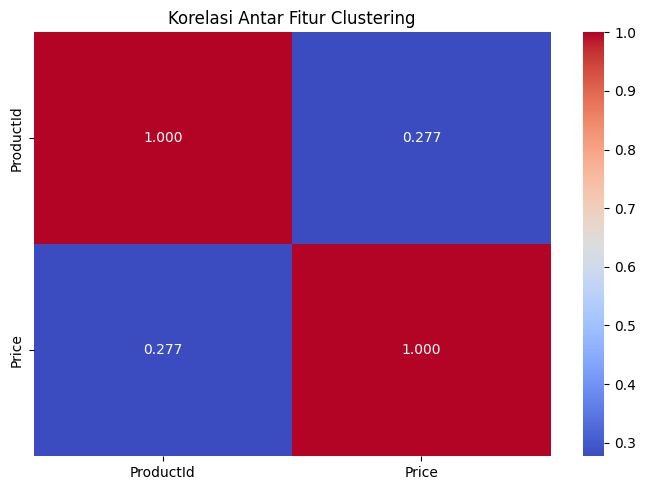

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation = products.corr(numeric_only=True)

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".3f",
    cmap="coolwarm"
)

plt.title("Korelasi Antar Fitur Clustering")
plt.tight_layout()
plt.show()

standarisasi

In [ ]:
from sklearn.preprocessing import StandardScaler

# 1. Pastikan X hanya berisi kolom numerik dan bebas dari nilai NaN
# Contoh: X = df[["TotalQuantity", "ActivityRatio"]].dropna()

scaler = StandardScaler()

# 2. Lakukan standarisasi
X_scaled = scaler.fit_transform(X)

# 3. Opsional: kembalikan ke DataFrame agar nama kolom tidak hilang
# import pandas as pd
# X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

In [ ]:
print("Mean:", X_scaled.mean(axis=0))
print("Std :", X_scaled.std(axis=0))

Mean: [-1.19762356e-15 -7.30385020e-15  5.13832475e-15]
Std : [1. 1. 1.]


Uji jumlah cluster K=2–10

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

evaluation = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)
    inertia = kmeans.inertia_
    silhouette = silhouette_score(X_scaled, labels)

    evaluation.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette": silhouette
    })

evaluation = pd.DataFrame(evaluation)
evaluation

,K,Inertia,Silhouette
0,2,151.843805,0.387723
1,3,114.336169,0.351555
2,4,79.885147,0.377788
3,5,64.148003,0.377396
4,6,52.776671,0.384181
5,7,45.817104,0.361672
6,8,40.526051,0.364328
7,9,35.752937,0.375218
8,10,32.491672,0.372881


Grafik Elbow

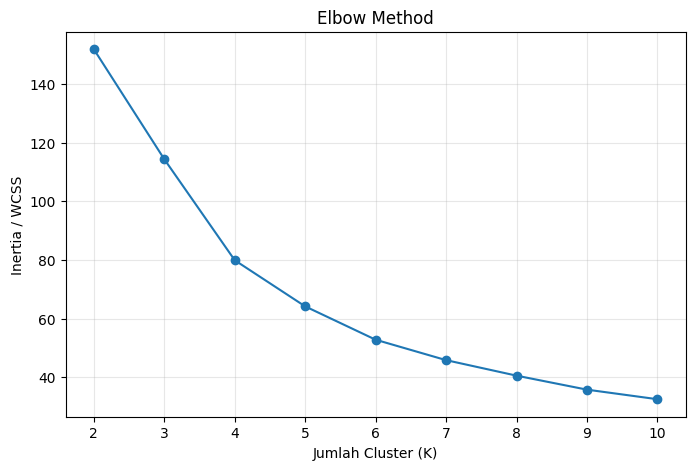

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    evaluation["K"],
    evaluation["Inertia"],
    marker="o"
)

plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Inertia / WCSS")
plt.title("Elbow Method")

plt.xticks(range(2, 11))
plt.grid(True, alpha=0.3)

plt.show()

Grafik Silhouette

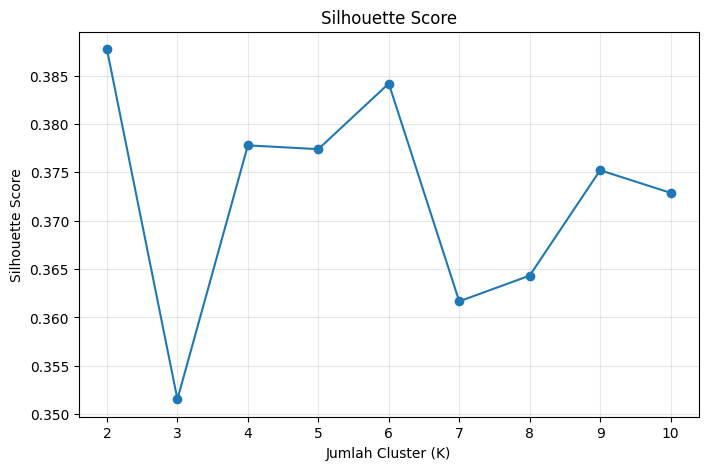

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    evaluation["K"],
    evaluation["Silhouette"],
    marker="o"
)

plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")

plt.xticks(range(2, 11))
plt.grid(True, alpha=0.3)

plt.show()

Cari K dengan silhouette tertinggi

In [ ]:
evaluation.loc[
    evaluation["Silhouette"].idxmax()
]

,0
K,2.000000
Inertia,151.843805
Silhouette,0.387723


Uji K=2

In [ ]:
kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels_2 = kmeans_2.fit_predict(X_scaled)

product_data["Cluster_K2"] = labels_2

In [ ]:
product_data["Cluster_K2"].value_counts().sort_index()

,count
Cluster_K2,
0,43
1,51


profiling K=2

In [ ]:
product_data.groupby("Cluster_K2")[feature_cols].mean()

,TotalQuantity,ActivityRatio,QuantityPerActiveDay
Cluster_K2,,,
0,682.720930,0.914330,2.745799
1,639.529412,0.894824,2.628050


uji K=4

In [ ]:
kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

labels_4 = kmeans_4.fit_predict(X_scaled)

product_data["Cluster"] = labels_4

In [ ]:
product_data["Cluster"].value_counts().sort_index()

,count
Cluster,
0,31
1,24
2,20
3,19


profil K=4

In [ ]:
profile_k4 = (
    product_data
    .groupby("Cluster")[feature_cols]
    .mean()
)

profile_k4

,TotalQuantity,ActivityRatio,QuantityPerActiveDay
Cluster,,,
0,653.419355,0.891841,2.693736
1,692.958333,0.912377,2.792737
2,623.750000,0.892096,2.571040
3,663.736842,0.924536,2.639347


uji K=6


In [ ]:
kmeans_6 = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

labels_6 = kmeans_6.fit_predict(X_scaled)

product_data["Cluster_K6"] = labels_6

In [ ]:
product_data["Cluster_K6"].value_counts().sort_index()

,count
Cluster_K6,
0,11
1,12
2,14
3,11
4,13
5,33


Setelah perbandingan K=2, K=4, dan K=6, kita gunakan K=4 karena memberikan segmentasi lebih granular dan seimbang.
Silhouette = 0.3778 (hanya 0.0099 di bawah K=2 = 0.3877),
dengan ukuran cluster 31, 24, 20, dan 19 produk.
K=4 dinilai lebih informatif dan mudah diinterpretasikan dibanding K=2 dan K=6.

In [ ]:
final_k = 4

In [ ]:
kmeans_final = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

final_labels = kmeans_final.fit_predict(X_scaled)

product_data["Cluster"] = final_labels

Hitung silhouette final

In [ ]:
overall_silhouette = silhouette_score(
    X_scaled,
    product_data["Cluster"]
)

print(overall_silhouette)

0.3777875854339562


Silhouette masing masing produk


In [ ]:
from sklearn.metrics import silhouette_samples

product_data["Silhouette"] = silhouette_samples(
    X_scaled,
    product_data["Cluster"]
)

product_data.head()

,ProductId,TotalQuantity,Frequency,ActiveSellingDays,ProductName,Variant,Category,ActivityRatio,QuantityPerActiveDay,Cluster_K2,Cluster,Cluster_K6,Silhouette
0,3,683,683,250,Air Mineral,-,Other,0.919118,2.732000,0,1,4,0.206090
1,4,641,641,242,Americano,Hot Houseblend,Coffee,0.889706,2.648760,1,0,5,0.301095
2,5,686,686,251,Americano,Ice Houesblend,Coffee,0.922794,2.733068,0,1,4,0.201503
3,6,706,706,244,Americano,Hot Arabica,Coffee,0.897059,2.893443,0,1,1,0.433368
4,7,633,633,242,Americano,Ice Arabica,Coffee,0.889706,2.615702,1,2,3,0.152460


statistik sillohouette

In [ ]:
product_data["Silhouette"].describe()

,Silhouette
count,94.000000
mean,0.377788
std,0.175108
min,-0.107047
25%,0.265301
50%,0.392004
75%,0.521641
max,0.649276


cari produk borderlie


In [ ]:
borderline_products = (
    product_data
    .sort_values("Silhouette")
    [
        [
            "ProductId",
            "ProductName",
            "Variant",
            "Category",
            "TotalQuantity",
            "ActivityRatio",
            "QuantityPerActiveDay",
            "Cluster",
            "Silhouette"
        ]
    ]
)

In [ ]:
borderline_products.head(10)

,ProductId,ProductName,Variant,Category,TotalQuantity,ActivityRatio,QuantityPerActiveDay,Cluster,Silhouette
77,80,Sitrus Cafe,-,Coffee,674,0.900735,2.751020,1,-0.107047
85,88,Vanilla Latte,-,Coffee,673,0.908088,2.724696,1,-0.034868
45,48,Friendly Coffee,Ice double shot,Coffee,648,0.908088,2.623482,3,-0.003889
80,83,Sunset,-,Other,674,0.908088,2.728745,1,0.020316
56,59,Hazelnut Latte (Gedhe),-,Menu Gedhe,692,0.933824,2.724409,1,0.032458
66,69,Matcha Latte (Gedhe),-,Menu Gedhe,631,0.878676,2.640167,2,0.034781
21,24,Burnt Sugar,-,Snacks,629,0.860294,2.688034,0,0.071602
38,41,Espresso Arabica,Basic Espresso,Coffee,640,0.915441,2.570281,3,0.085097
29,32,Cappuccino,Ice Arabica,Coffee,617,0.926471,2.448413,2,0.096848
33,36,Cold Brew,-,Coffee,628,0.875000,2.638655,2,0.099406


sitrus cafe masuk cluster  karena

TOP 5 produk paling repreentatif setiap cluster

In [ ]:
top_products = (
    product_data
    .sort_values(
        ["Cluster", "Silhouette"],
        ascending=[True, False]
    )
    .groupby("Cluster")
    .head(5)
)

In [ ]:
top_products[
    [
        "Cluster",
        "ProductName",
        "Variant",
        "Category",
        "TotalQuantity",
        "ActivityRatio",
        "QuantityPerActiveDay",
        "Silhouette"
    ]
]

,Cluster,ProductName,Variant,Category,TotalQuantity,ActivityRatio,QuantityPerActiveDay,Silhouette
9,0,BLACK,Arabica,Menu Gedhe,658,0.889706,2.719008,0.649276
87,0,WHITE,-,Menu Gedhe,658,0.889706,2.719008,0.649276
74,0,Red Apple,-,Tea,655,0.886029,2.717842,0.640680
70,0,Nostaltea,-,Tea,654,0.886029,2.713693,0.637119
12,0,Basic Latte,Hot Arabica,Coffee,659,0.889706,2.723140,0.631182
84,1,Upgrade Beans (Arabica),-,Add on,698,0.911765,2.814516,0.608876
34,1,Chocolate (Gedhe),-,Menu Gedhe,700,0.915441,2.811245,0.605859
8,1,BLACK,Houseblend,Menu Gedhe,704,0.915441,2.827309,0.599562
22,1,Butterscotch,-,Coffee,701,0.919118,2.804000,0.575946
35,1,Creamy Klepon,-,Other,694,0.908088,2.809717,0.571131


centroid k=4

In [ ]:
centroids_scaled = kmeans_final.cluster_centers_

In [ ]:
centroids_original = scaler.inverse_transform(
    centroids_scaled
)

centroid_df = pd.DataFrame(
    centroids_original,
    columns=feature_cols
)

centroid_df.index.name = "Cluster"

centroid_df

,TotalQuantity,ActivityRatio,QuantityPerActiveDay
Cluster,,,
0,653.419355,0.891841,2.693736
1,692.958333,0.912377,2.792737
2,623.750000,0.892096,2.571040
3,663.736842,0.924536,2.639347


estimated active days

In [ ]:
centroid_df["EstimatedActiveDays"] = (
    centroid_df["ActivityRatio"] * total_days
)

centroid_df

,TotalQuantity,ActivityRatio,QuantityPerActiveDay,EstimatedActiveDays
Cluster,,,,
0,653.419355,0.891841,2.693736,242.580645
1,692.958333,0.912377,2.792737,248.166667
2,623.750000,0.892096,2.571040,242.650000
3,663.736842,0.924536,2.639347,251.473684


profil kategori setiap cluster

In [ ]:
category_crosstab = pd.crosstab(
    product_data["Cluster"],
    product_data["Category"]
)

category_crosstab

Category,Add on,Coffee,Menu Gedhe,Other,Snacks,Tea
Cluster,,,,,,
0,3,9,6,4,4,5
1,1,8,5,7,0,3
2,0,7,4,3,2,4
3,0,10,4,1,3,1


In [ ]:
category_percentage = (
    pd.crosstab(
        product_data["Cluster"],
        product_data["Category"],
        normalize="index"
    ) * 100
)

category_percentage.round(2)

Category,Add on,Coffee,Menu Gedhe,Other,Snacks,Tea
Cluster,,,,,,
0,9.68,29.03,19.35,12.90,12.90,16.13
1,4.17,33.33,20.83,29.17,0.00,12.50
2,0.00,35.00,20.00,15.00,10.00,20.00
3,0.00,52.63,21.05,5.26,15.79,5.26


dataset FINAL


In [ ]:
final_product_cluster = product_data[
    [
        "ProductId",
        "ProductName",
        "Variant",
        "Category",
        "TotalQuantity",
        "ActivityRatio",
        "QuantityPerActiveDay",
        "Cluster",
        "Silhouette"
    ]
].copy()

In [ ]:
final_product_cluster.shape

(94, 9)

Urutkan berdasarkan cluster


In [ ]:
final_product_cluster = (
    final_product_cluster
    .sort_values(
        ["Cluster", "TotalQuantity"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

In [ ]:
final_product_cluster.head(20)

,ProductId,ProductName,Variant,Category,TotalQuantity,ActivityRatio,QuantityPerActiveDay,Cluster,Silhouette
0,95,Waffle,-,Snacks,672,0.900735,2.742857,0,0.152686
1,23,Black Rice,Hot,Other,668,0.889706,2.760331,0,0.379002
2,43,Espresso Houseblend,Basic Espresso,Coffee,667,0.900735,2.722449,0,0.380623
3,82,Summer,-,Tea,667,0.889706,2.756198,0,0.414417
4,9,Apple Pie Latte (Gedhe),-,Menu Gedhe,664,0.900735,2.710204,0,0.460313
5,57,Happy Moca,Ice,Coffee,664,0.904412,2.699187,0,0.309746
6,78,Red Liquid,-,Other,664,0.900735,2.710204,0,0.460313
7,15,Basic Latte,Hot Arabica,Coffee,659,0.889706,2.723140,0,0.631182
8,12,BLACK,Arabica,Menu Gedhe,658,0.889706,2.719008,0,0.649276
9,90,WHITE,-,Menu Gedhe,658,0.889706,2.719008,0,0.649276


In [ ]:
final_product_cluster.to_csv(
    "final_product_cluster.csv",
    index=False
)

In [ ]:
files.download("final_product_cluster.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
evaluation.to_csv(
    "evaluasi_kmeans_k2_k10.csv",
    index=False
)

files.download("evaluasi_kmeans_k2_k10.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
borderline_products.head(10).to_csv(
    "10_produk_borderline.csv",
    index=False
)

files.download("10_produk_borderline.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

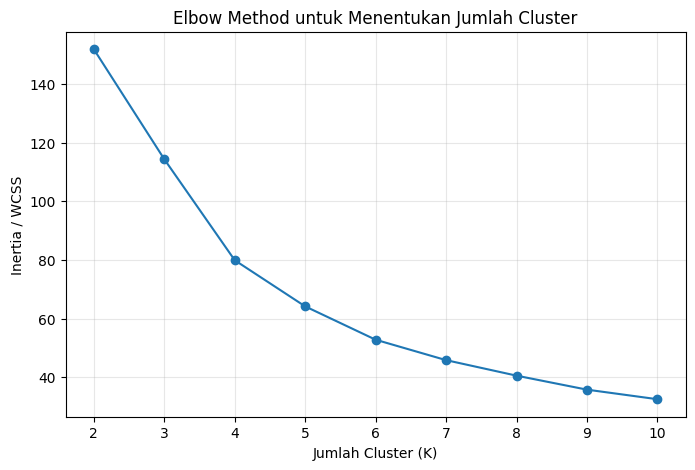

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    evaluation["K"],
    evaluation["Inertia"],
    marker="o"
)

plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Inertia / WCSS")
plt.title("Elbow Method untuk Menentukan Jumlah Cluster")

plt.xticks(range(2, 11))
plt.grid(True, alpha=0.3)

plt.show()

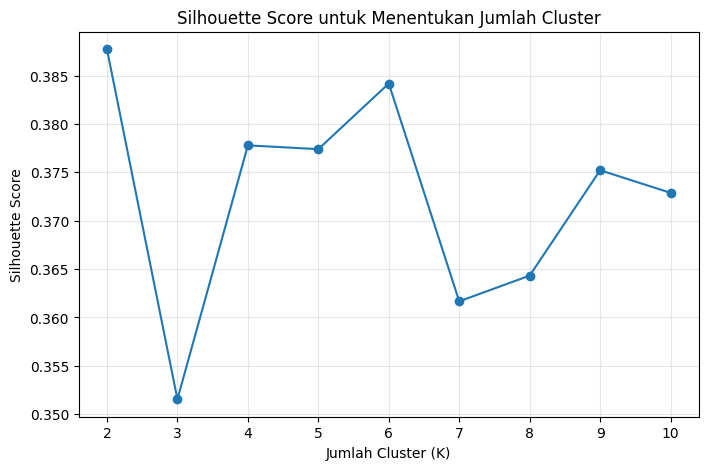

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    evaluation["K"],
    evaluation["Silhouette"],
    marker="o"
)

plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score untuk Menentukan Jumlah Cluster")

plt.xticks(range(2, 11))
plt.grid(True, alpha=0.3)

plt.show()

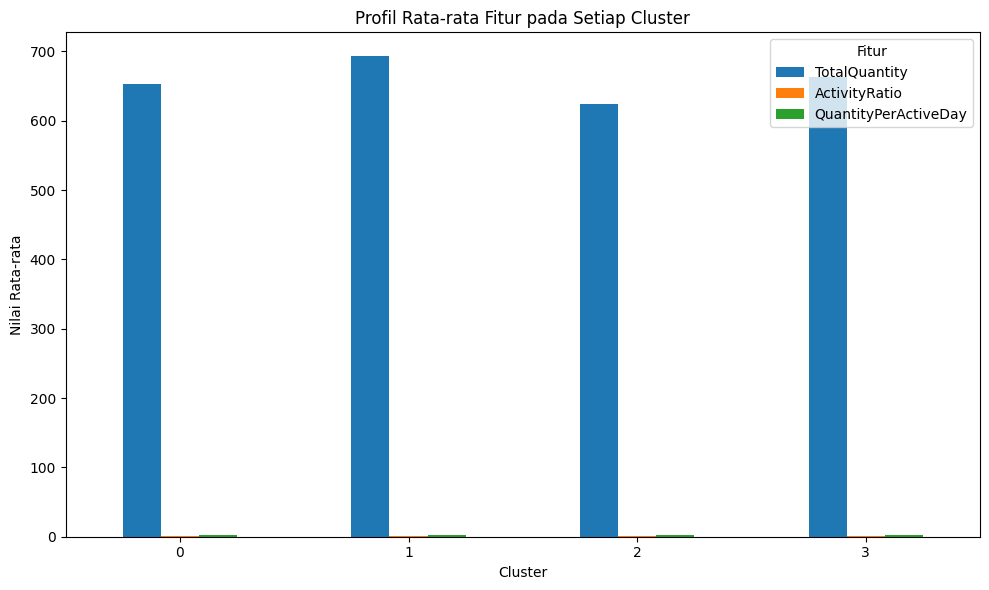

In [ ]:
profile_plot = product_data.groupby("Cluster")[feature_cols].mean()

profile_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Cluster")
plt.ylabel("Nilai Rata-rata")
plt.title("Profil Rata-rata Fitur pada Setiap Cluster")

plt.xticks(rotation=0)
plt.legend(title="Fitur")
plt.tight_layout()

plt.show()